In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from sklearn.model_selection import train_test_split, TimeSeriesSplit
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import f1_score, accuracy_score, roc_curve, roc_auc_score, average_precision_score, precision_recall_curve, classification_report


import eli5
from eli5.sklearn import PermutationImportance

import shap

# 1. Preprocessing and cleaning data

In [2]:
## import data
city_df = pd.read_csv('city_hotel.csv')
resort_df = pd.read_csv('resort_hotel.csv')

## Combine the two datasets
city_df['HotelType'] = 'city'
resort_df['HotelType'] = 'resort'

df = pd.concat([city_df, resort_df], axis = 0, ignore_index=True)
df.head()

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate,HotelType
0,0,6,2015,July,27,1,0,2,1,0.0,...,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03,city
1,1,88,2015,July,27,1,0,4,2,0.0,...,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01,city
2,1,65,2015,July,27,1,0,4,1,0.0,...,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30,city
3,1,92,2015,July,27,1,2,4,2,0.0,...,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23,city
4,1,100,2015,July,27,2,0,2,2,0.0,...,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02,city


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   IsCanceled                   119390 non-null  int64  
 1   LeadTime                     119390 non-null  int64  
 2   ArrivalDateYear              119390 non-null  int64  
 3   ArrivalDateMonth             119390 non-null  object 
 4   ArrivalDateWeekNumber        119390 non-null  int64  
 5   ArrivalDateDayOfMonth        119390 non-null  int64  
 6   StaysInWeekendNights         119390 non-null  int64  
 7   StaysInWeekNights            119390 non-null  int64  
 8   Adults                       119390 non-null  int64  
 9   Children                     119386 non-null  float64
 10  Babies                       119390 non-null  int64  
 11  Meal                         119390 non-null  object 
 12  Country                      118902 non-null  object 
 13 

## Variables description
Sensitive information were replaced with codes.

| Feature | Data Type | Description |
| :--- | :--- | :--- |
| ADR | Numeric | Average Daily Rate |
| Adults | Integer | Number of adults |
| Agent | Categorical | ID of the travel agency that made the booking |
| ArrivalDateDayOfMonth | Integer | Day of the month of the arrival date |
| ArrivalDateMonth | Categorical | Month of arrival date with 12 categories: “January” to “December”
| ArrivalDateYear | Integer | Year of arrival date
| Babies | Integer | Number of babies
| BookingChanges | Integer | Number of changes/amendments made to the booking from the moment the booking was entered on the PMS until the moment of check-in or cancellation
| Children | Integer | Number of children
| Company | Categorical | Code of the company/entity that made the booking or responsible for paying the booking. 
| Country | Categorical | Country of origin
| CustomerType | Categorical | Type of booking, assuming one of four categories: <br>1. Contract - when the booking has an allotment or other type of contract associated to it; <br>2. Group – when the booking is associated to a group; <br>3. Transient – when the booking is not part of a group or contract, and is not associated to other transient booking; <br>4. Transient-party – when the booking is transient, but is associated to at least other transient booking
| DaysInWaitingList | Integer | Number of days the booking was in the waiting list before it was confirmed to the customer
| DepositType | Categorical | Indication on if the customer made a deposit to guarantee the booking. This variable can assume three categories: <br>1. No Deposit – no deposit was made; <br>2. Non Refund – a deposit was made in the value of the total stay cost; <br>3. Refundable – a deposit was made with a value under the total cost of stay.
 | DistributionChannel | Categorical | Booking distribution channel. The term “TA” means “Travel Agents” and “TO” means “Tour Operators”
| HotelType | Categorical | "city" means city hotels whereas "resort" means resort hotels.
| IsRepeatedGuest | Categorical | Value indicating if the booking name was from a repeated guest (1) or not (0)
| LeadTime | Integer | Number of days that elapsed between the entering date of the booking into the PMS and the arrival date
| MarketSegment | Categorical | Market segment designation. In categories, the term “TA” means “Travel Agents” and “TO” means “Tour Operators”
| Meal | Categorical | Type of meal booked. Categories are presented in standard hospitality meal packages: <br>1. Undefined/SC – no meal package;<br>2. BB – Bed & Breakfast;<br>3. HB – Half board (breakfast and one other meal – usually dinner);<br>4. FB – Full board (breakfast, lunch and dinner)
| PreviousBookingsNotCanceled | Integer | Number of previous bookings not cancelled by the customer prior to the current booking
| PreviousCancellations | Integer | Number of previous bookings that were cancelled by the customer prior to the current booking
| RequiredCardParkingSpaces | Integer | Number of car parking spaces required by the customer
| ReservedRoomType | Categorical | Code of room type reserved. Code is presented instead of designation for anonymity reasons
| StaysInWeekendNights | Integer | Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel
| StaysInWeekNights | Integer | Number of week nights (Monday to Friday) the guest stayed or booked to stay at the hotel
| TotalOfSpecialRequests | Integer | Number of special requests made by the customer (e.g. twin bed or high floor)
| ArrivalDateWeekNumber<br><mark>(to be discarded)</mark> | Integer | Week number of the arrival date. 'ArrivalDateDayOfMonth', 'ArrivalDateMonth', 'ArrivalDateYear' have fully provided enough information about the date. This column is redundant.
| AssignedRoomType<br><mark>(to be discarded)</mark> | Categorical | Code for the type of room finally assigned to the customers. Sometimes the assigned room type differs from the reserved room type due to hotel operation reasons (e.g. overbooking) or by customer request. Code is presented instead of designation for anonymity reasons. This information is irrelevant and should be dropped.
| ReservationStatus<br><mark>(to be discarded)</mark> | Categorical | Reservation last status, assuming one of three categories:<br>1. Canceled <br>2. Check-Out <br>3. No-Show. <br>This variable describes the same information as our prediction outcome, to avoid data leakage it should be dropped.
| ReservationStatusDate<br><mark>(to be discarded)</mark>  | Date | Date at which the ReservationStatus was set. As ReservationStatus should be removed, this variable is useless as well.
| IsCanceled<br>(Outcome) | Categorical | 	Value indicating if the booking was canceled (1) or not (0)

In [4]:
## Select one cancelled case to better understanding the meaning of the variables  
df[df['IsCanceled'] == 1].iloc[1]

IsCanceled                                    1
LeadTime                                     65
ArrivalDateYear                            2015
ArrivalDateMonth                           July
ArrivalDateWeekNumber                        27
ArrivalDateDayOfMonth                         1
StaysInWeekendNights                          0
StaysInWeekNights                             4
Adults                                        1
Children                                    0.0
Babies                                        0
Meal                                  BB       
Country                                     PRT
MarketSegment                         Online TA
DistributionChannel                       TA/TO
IsRepeatedGuest                               0
PreviousCancellations                         0
PreviousBookingsNotCanceled                   0
ReservedRoomType               A               
AssignedRoomType               A               
BookingChanges                          

In [5]:
## drop inappropriate columns
df = df.drop(columns=['ReservationStatus', 'ReservationStatusDate', 'AssignedRoomType', 'ArrivalDateWeekNumber'])

## drop duplicates
df = df.drop_duplicates()

## drop null values
df = df.dropna()
print(df.isna().sum()) # summary of null values 

IsCanceled                     0
LeadTime                       0
ArrivalDateYear                0
ArrivalDateMonth               0
ArrivalDateDayOfMonth          0
StaysInWeekendNights           0
StaysInWeekNights              0
Adults                         0
Children                       0
Babies                         0
Meal                           0
Country                        0
MarketSegment                  0
DistributionChannel            0
IsRepeatedGuest                0
PreviousCancellations          0
PreviousBookingsNotCanceled    0
ReservedRoomType               0
BookingChanges                 0
DepositType                    0
Agent                          0
Company                        0
DaysInWaitingList              0
CustomerType                   0
ADR                            0
RequiredCarParkingSpaces       0
TotalOfSpecialRequests         0
HotelType                      0
dtype: int64


In [6]:
numeric_col = ['LeadTime','StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'PreviousCancellations', 'PreviousBookingsNotCanceled',
              'BookingChanges', 'DaysInWaitingList', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests']   

categorical_col = ['ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateDayOfMonth', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'ReservedRoomType', 'DepositType', 'Agent', 'Company', 'CustomerType', 'HotelType']

## Handling numeric variables

In [7]:
## Spot problematic numeric columns
prob_numeric_col = []

for x in numeric_col:
    if df[x].dtype == 'O': # if any words have been input into a numeric column, the datatype will become object.  
        prob_numeric_col.append(x)

print(prob_numeric_col) # No probmatic numeric columns found at this stage

[]


In [8]:
## Preparations for outliers removal
df[numeric_col].describe()

## Except StaysInWeekendNights, StaysInWeekNights, all columns have suspicous max values
prob_numeric_col = ['LeadTime', 'Adults', 'Children', 'Babies', 'PreviousCancellations', 'PreviousBookingsNotCanceled',
              'BookingChanges', 'DaysInWaitingList', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests'] 
print(f'There are {len(prob_numeric_col)} suspicous numeric columns.') 

There are 11 suspicous numeric columns.


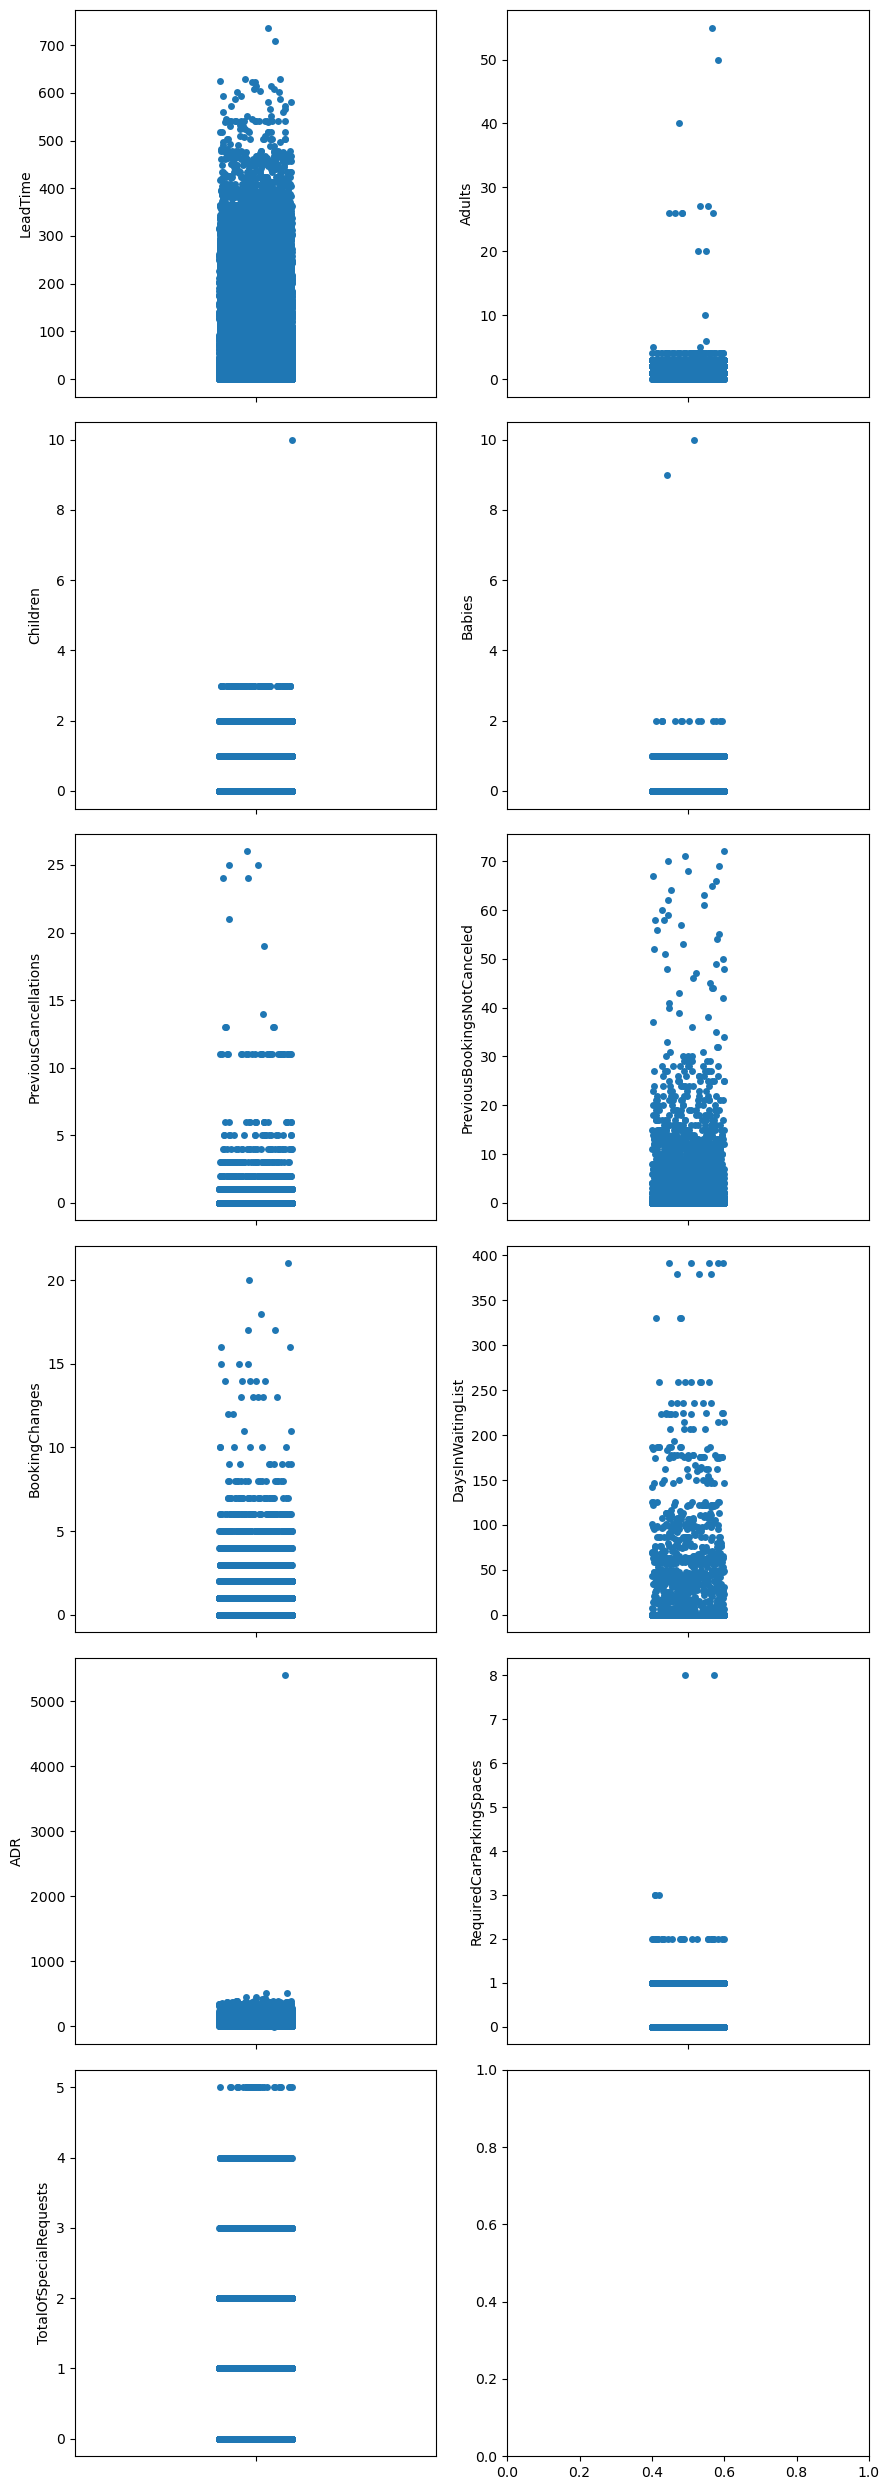

In [9]:
## Draw stripplot to spot out outliers

def plot_multiple_stripplots(df: pd.DataFrame, col_list: list):
    """Pass the dataframe and the column list to draw strip plots for chosen columns. The list specifies which columns to include."""

    ## Determine the row count of the subplot
    if len(col_list)%2 == 0:
        subplot_row_count = int(len(col_list)/2)
    else:
        subplot_row_count = int(len(col_list)/2) + 1
        
    fig, axes = plt.subplots(subplot_row_count, 2, figsize=(9, 25))
    axes = axes.flatten() 

    ## Plot the graph
    for i, col in enumerate(col_list):
        sns.stripplot(data=df, y=col, ax=axes[i]) 
        
    plt.tight_layout()
    plt.show()

plot_multiple_stripplots(df, prob_numeric_col)

> **Comments**:
>- From the above plot, 'LeadTime', 'Adults', 'Children', 'Babies', 'ADR' and 'RequiredCarParkingSpaces' have outliers or unreasonable values.
>- It is puzzling to have 10 or more adults leaving in one hotel room. Having 8-10 children or babies in one family is also puzzling.



In [10]:
## Drop outliers for LeadTime and ADR
df = df[(df['LeadTime'] < 650) & (df['ADR'] < 1000)]

In [11]:
prob_numeric_col = ['Adults', 'Children', 'Babies', 'RequiredCarParkingSpaces']
for col in prob_numeric_col:
    print(f'Here are the unique values for {col}')
    sorted_unique_value = np.sort(df[col].unique())
    print(sorted_unique_value)
    print('\n')

Here are the unique values for Adults
[ 0  1  2  3  4  5  6 10 20 26 27 40 50 55]


Here are the unique values for Children
[ 0.  1.  2.  3. 10.]


Here are the unique values for Babies
[ 0  1  2  9 10]


Here are the unique values for RequiredCarParkingSpaces
[0 1 2 3 8]




In [12]:
## Drop outliers for Adults, Children, Babies, RequiredCarParkingSpaces
mask = (df['Adults'] < 8) & (df['Children'] < 8) & (df['Babies'] < 8) & (df['RequiredCarParkingSpaces'] < 8) 
df = df[mask]

## Handling categorical variables

In [13]:
categorical_col 

['ArrivalDateYear',
 'ArrivalDateMonth',
 'ArrivalDateDayOfMonth',
 'Meal',
 'Country',
 'MarketSegment',
 'DistributionChannel',
 'IsRepeatedGuest',
 'ReservedRoomType',
 'DepositType',
 'Agent',
 'Company',
 'CustomerType',
 'HotelType']

In [14]:
# Spot problematic categorical columns
for col in categorical_col:
    print(f'Here are the unique values for {col}')
    print(df[col].unique())
    print('\n')

Here are the unique values for ArrivalDateYear
[2015 2016 2017]


Here are the unique values for ArrivalDateMonth
['July' 'August' 'September' 'October' 'November' 'December' 'January'
 'February' 'March' 'April' 'May' 'June']


Here are the unique values for ArrivalDateDayOfMonth
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31]


Here are the unique values for Meal
['HB       ' 'BB       ' 'SC       ' 'FB       ' 'Undefined']


Here are the unique values for Country
['PRT' 'ITA' 'ESP' 'DEU' 'FRA' 'NLD' 'GBR' 'ROU' 'BRA' 'SWE' 'AUT' 'AGO'
 'BEL' 'CHE' 'NOR' 'RUS' 'ISR' 'IRL' 'POL' 'CHN' 'USA' 'MAR' 'AUS' 'MOZ'
 'TUN' 'DNK' 'MEX' 'GRC' 'DZA' 'COL' 'LUX' 'CN' 'LVA' 'FIN' 'HRV' 'STP'
 'BGR' 'UKR' 'VEN' 'TWN' 'IRN' 'KOR' 'TUR' 'BLR' 'JPN' 'CZE' 'HUN' 'AZE'
 'KAZ' 'IND' 'NZL' 'IDN' 'LTU' 'LBN' 'SRB' 'SVN' 'SVK' 'MYS' 'CMR' 'CHL'
 'ARG' 'SGP' 'SEN' 'PER' 'EGY' 'SAU' 'KNA' 'JOR' 'ZAF' 'THA' 'KWT' 'LKA'
 'ALB' 'ETH' 'PHL' 'ARE' 'ECU' 'OMN' 'IRQ' '

In [15]:
## Strip the string values and fill back np.nan values 
def strip_and_fill_na(word: str) -> str | float:
    """ strip word or return np.nan if NULL is written"""
    word = word.strip()
    return word if (word != 'NULL') else np.nan


prob_categorical_col = ['Meal', 'ReservedRoomType', 'DepositType', 'Agent', 'Company']
for col in prob_categorical_col:
    df[col] = df[col].map(strip_and_fill_na)




In [16]:
## Check whether the mapping is successful or not
print(f'Number of null values:\n{df.isna().sum()}')

for col in categorical_col:
    print(f'Here are the unique values for {col}')
    print(df[col].unique()) 
    print('\n')

## As the majority values in 'Company' column is NA, it is advisable to drop the whole column. 
df.drop(columns=['Company'], inplace=True)

## na values for agent are dropped as well
df.dropna(inplace=True)

Number of null values:
IsCanceled                         0
LeadTime                           0
ArrivalDateYear                    0
ArrivalDateMonth                   0
ArrivalDateDayOfMonth              0
StaysInWeekendNights               0
StaysInWeekNights                  0
Adults                             0
Children                           0
Babies                             0
Meal                               0
Country                            0
MarketSegment                      0
DistributionChannel                0
IsRepeatedGuest                    0
PreviousCancellations              0
PreviousBookingsNotCanceled        0
ReservedRoomType                   0
BookingChanges                     0
DepositType                        0
Agent                          11614
Company                        80732
DaysInWaitingList                  0
CustomerType                       0
ADR                                0
RequiredCarParkingSpaces           0
TotalOfSpecialR

In [17]:
## Change the wording in 'Meal' and 'DistributionChannel' columns for better understanding
mapping = {
    'SC' : 'No meal',
    'Undefined': 'No meal'
}
    
df['Meal'] = df['Meal'].replace(mapping)
print(f'Here are the unique values for "Meal": {df['Meal'].unique()}')

df['DistributionChannel'] = df['DistributionChannel'].replace('Undefined', 'Other')
print(f'Here are the unique values for "DistributionChannel": {df['DistributionChannel'].unique()}')

Here are the unique values for "Meal": ['HB' 'BB' 'No meal' 'FB']
Here are the unique values for "DistributionChannel": ['TA/TO' 'Direct' 'Corporate' 'GDS']


# 2. Descriptive Statistics

## Outcome (IsCanceled)

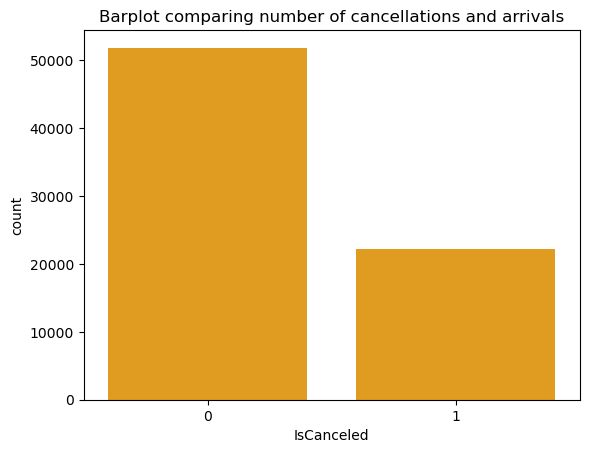

No. of people cancelled: 22209
No. of people arrived: 51851


In [18]:
## Comparing cancellation and arrival visually
plt.title('Barplot comparing number of cancellations and arrivals')
sns.countplot(data=df, x='IsCanceled', color='orange') 
plt.show()

## Comparing cancellation and arrival with statistics
print(f'No. of people cancelled: {df['IsCanceled'].sum()}')
print(f'No. of people arrived: {df['IsCanceled'].count() - df['IsCanceled'].sum()}')

> **Comments**:  
>The outcome variable is imbalanced. As the ratio of postive to negative is around 2:5, we have sufficient positive data to train model.

In [19]:
## Overview of the cleaned data
print(df.info())

df.describe()


<class 'pandas.core.frame.DataFrame'>
Index: 74060 entries, 0 to 119389
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   74060 non-null  int64  
 1   LeadTime                     74060 non-null  int64  
 2   ArrivalDateYear              74060 non-null  int64  
 3   ArrivalDateMonth             74060 non-null  object 
 4   ArrivalDateDayOfMonth        74060 non-null  int64  
 5   StaysInWeekendNights         74060 non-null  int64  
 6   StaysInWeekNights            74060 non-null  int64  
 7   Adults                       74060 non-null  int64  
 8   Children                     74060 non-null  float64
 9   Babies                       74060 non-null  int64  
 10  Meal                         74060 non-null  object 
 11  Country                      74060 non-null  object 
 12  MarketSegment                74060 non-null  object 
 13  DistributionChannel 

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,BookingChanges,DaysInWaitingList,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests
count,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000,74060.000000
mean,0.299878,86.283851,2016.231488,15.790818,1.074548,2.758939,1.925695,0.150365,0.010397,0.014758,0.019660,0.033297,0.248474,0.690427,110.399486,0.073049,0.745625
std,0.458208,85.441308,0.680144,8.851870,1.033666,2.047174,0.479478,0.472434,0.102889,0.120585,0.317878,0.512419,0.699910,9.770628,50.961451,0.261719,0.833843
min,0.000000,0.000000,2015.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,76.290000,0.000000,0.000000
50%,0.000000,59.000000,2016.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,102.000000,0.000000,1.000000
75%,1.000000,133.000000,2017.000000,24.000000,2.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,137.635000,0.000000,1.000000
max,1.000000,629.000000,2017.000000,31.000000,16.000000,41.000000,4.000000,3.000000,2.000000,1.000000,26.000000,50.000000,18.000000,391.000000,510.000000,3.000000,5.000000


## Numeric variables

In [20]:
numeric_col 

['LeadTime',
 'StaysInWeekendNights',
 'StaysInWeekNights',
 'Adults',
 'Children',
 'Babies',
 'PreviousCancellations',
 'PreviousBookingsNotCanceled',
 'BookingChanges',
 'DaysInWaitingList',
 'ADR',
 'RequiredCarParkingSpaces',
 'TotalOfSpecialRequests']

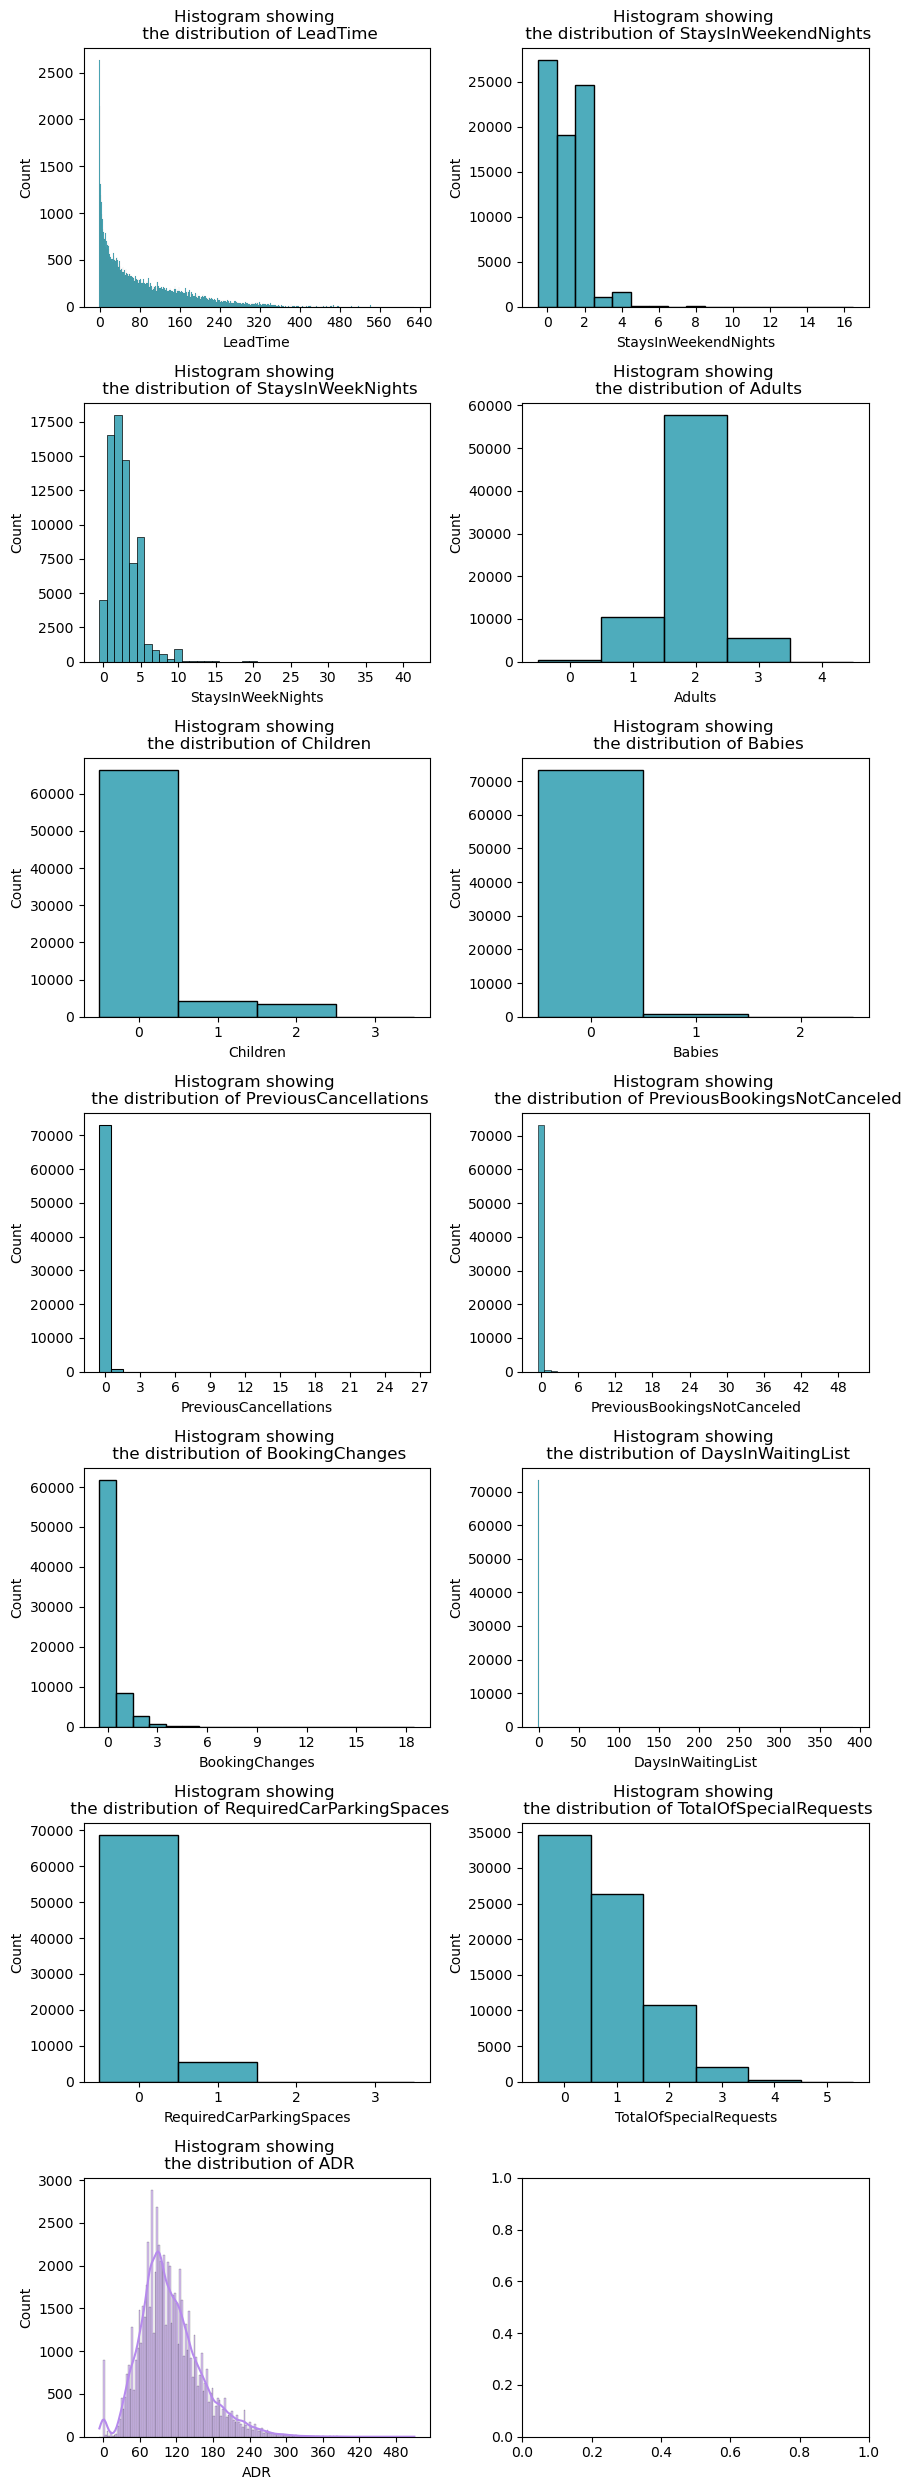

In [21]:
def plot_for_numeric_variables(df: pd.DataFrame, discrete_variable_list: list, continous_variable_list: list):
    """Pass the dataframe and include both discrete_variable_list and continous_variable_list to plot histograms """

    ## Determine the row count of the subplot
    subplots_count = len(discrete_variable_list) + len(continous_variable_list)
    if subplots_count % 2 == 0:
        subplot_row_count = int(subplots_count / 2)
    else:
        subplot_row_count = int(subplots_count / 2) + 1
        
    fig, axes = plt.subplots(subplot_row_count, 2, figsize=(9, 25))
    axes = axes.flatten() 

    ## Plot the plots for discrete variables
    for i, col in enumerate(discrete_variable_list):
        ax = axes[i]
        ax.set_title(f'Histogram showing \n the distribution of {col}')
        sns.histplot(data=df, x=col, ax=ax, discrete=True, color='#1290a6') 
        ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True)) # integrer=True is set to avoid bin on [-0.5, 0.5]

    ## Plot the plots for continous variables
    for i_2, col in enumerate(continous_variable_list):
        ax = axes[(i_2 + 1) + i]
        ax.set_title(f'Histogram showing \n the distribution of {col}')
        sns.histplot(data=df, x=col, kde=True, ax=ax, color='#b68aed')
        ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
        
    plt.tight_layout()
    plt.show()

discrete_variable_list = ['LeadTime',
 'StaysInWeekendNights',
 'StaysInWeekNights',
 'Adults',
 'Children',
 'Babies',
 'PreviousCancellations',
 'PreviousBookingsNotCanceled',
 'BookingChanges',
 'DaysInWaitingList',
 'RequiredCarParkingSpaces',
 'TotalOfSpecialRequests']
continous_variable_list = ['ADR'] 
plot_for_numeric_variables(df, discrete_variable_list, continous_variable_list)



> **Comments**:
>- Some columns are positively skewed. Unlike linear regression or some algorithm like Naive Bayesian, skewness is not a problem for tree-based model like XGboost. 

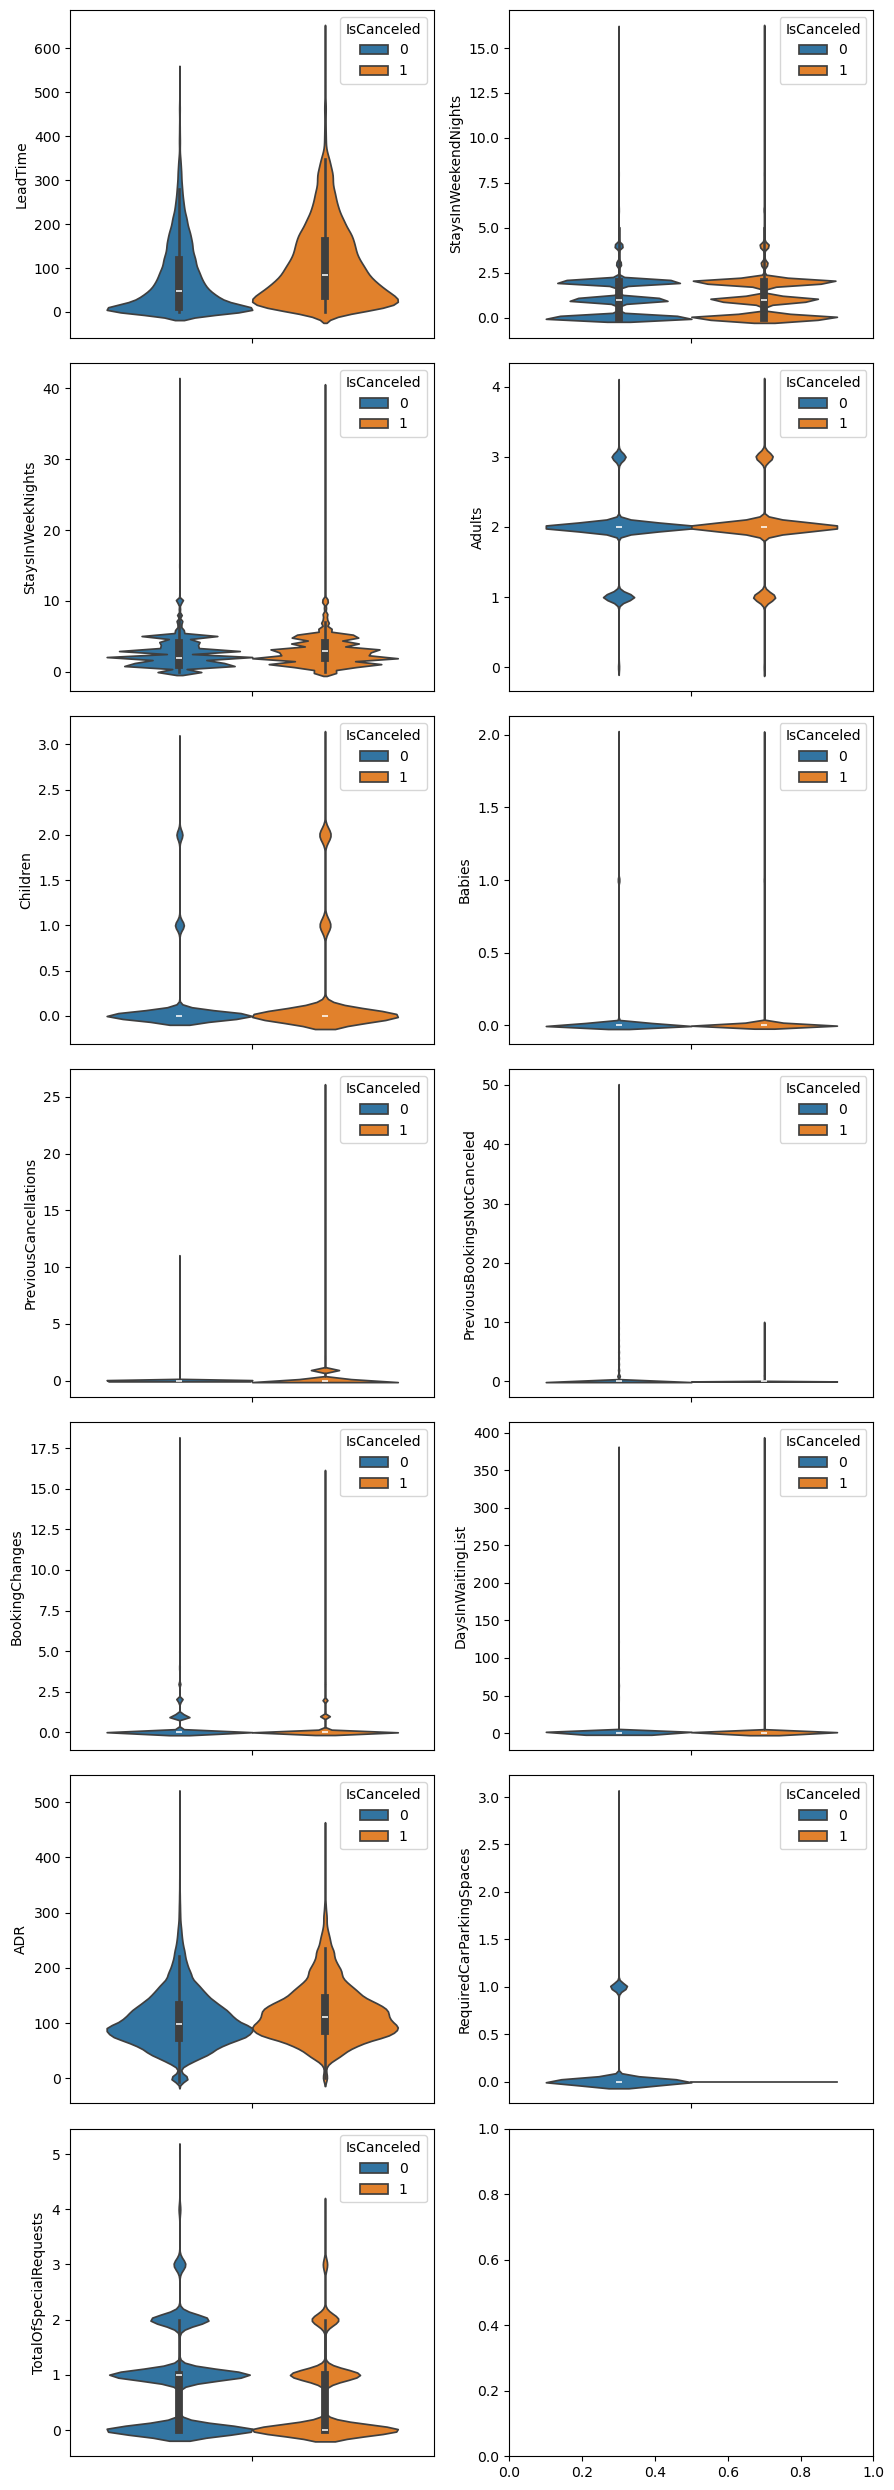

In [22]:
def plot_violinplots(df: pd.DataFrame, col_list: list):
    """Pass the dataframe and the column list to draw violin plots for chosen columns. The list specifies which columns to include."""

    ## Determine the row count of the subplot
    if len(col_list)%2 == 0:
        subplot_row_count = int(len(col_list)/2)
    else:
        subplot_row_count = int(len(col_list)/2) + 1
        
    fig, axes = plt.subplots(subplot_row_count, 2, figsize=(9, 25))
    axes = axes.flatten() 

    ## Plot the graph
    for i, col in enumerate(col_list):
        sns.violinplot(data=df, y=col, hue='IsCanceled', ax=axes[i]) 
        
    plt.tight_layout()
    plt.show()

plot_violinplots(df, numeric_col)

In [23]:
## Investigate into the situation of RequiredCarParkingSpaces

print('Required Car Parking Spaces data for people did not cancel:')
print(df[df['IsCanceled']== 0].describe()['RequiredCarParkingSpaces'])

print()

print('Required Car Parking Spaces data for people cancelled:')
print(df[df['IsCanceled']== 1].describe()['RequiredCarParkingSpaces'])  

Required Car Parking Spaces data for people did not cancel:
count    51851.000000
mean         0.104337
std          0.307525
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          3.000000
Name: RequiredCarParkingSpaces, dtype: float64

Required Car Parking Spaces data for people cancelled:
count    22209.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: RequiredCarParkingSpaces, dtype: float64


>**Comments**:  
>- People who cancelled had never requested for car parking. Concerns for data leakage might be raised but as we reference another column with a similar nature (TotalOfSpecialrequests), it is confident that these requests were made before the check-ins instead of on spot.
>- Another potentially useful predictor is LeadTime, which guests with longer lead time were likely to cancel.

### Categorical variables

In [24]:
categorical_col = ['ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateDayOfMonth','Meal',
 'Country', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'ReservedRoomType', 'DepositType', 'Agent', 'CustomerType',
 'HotelType']

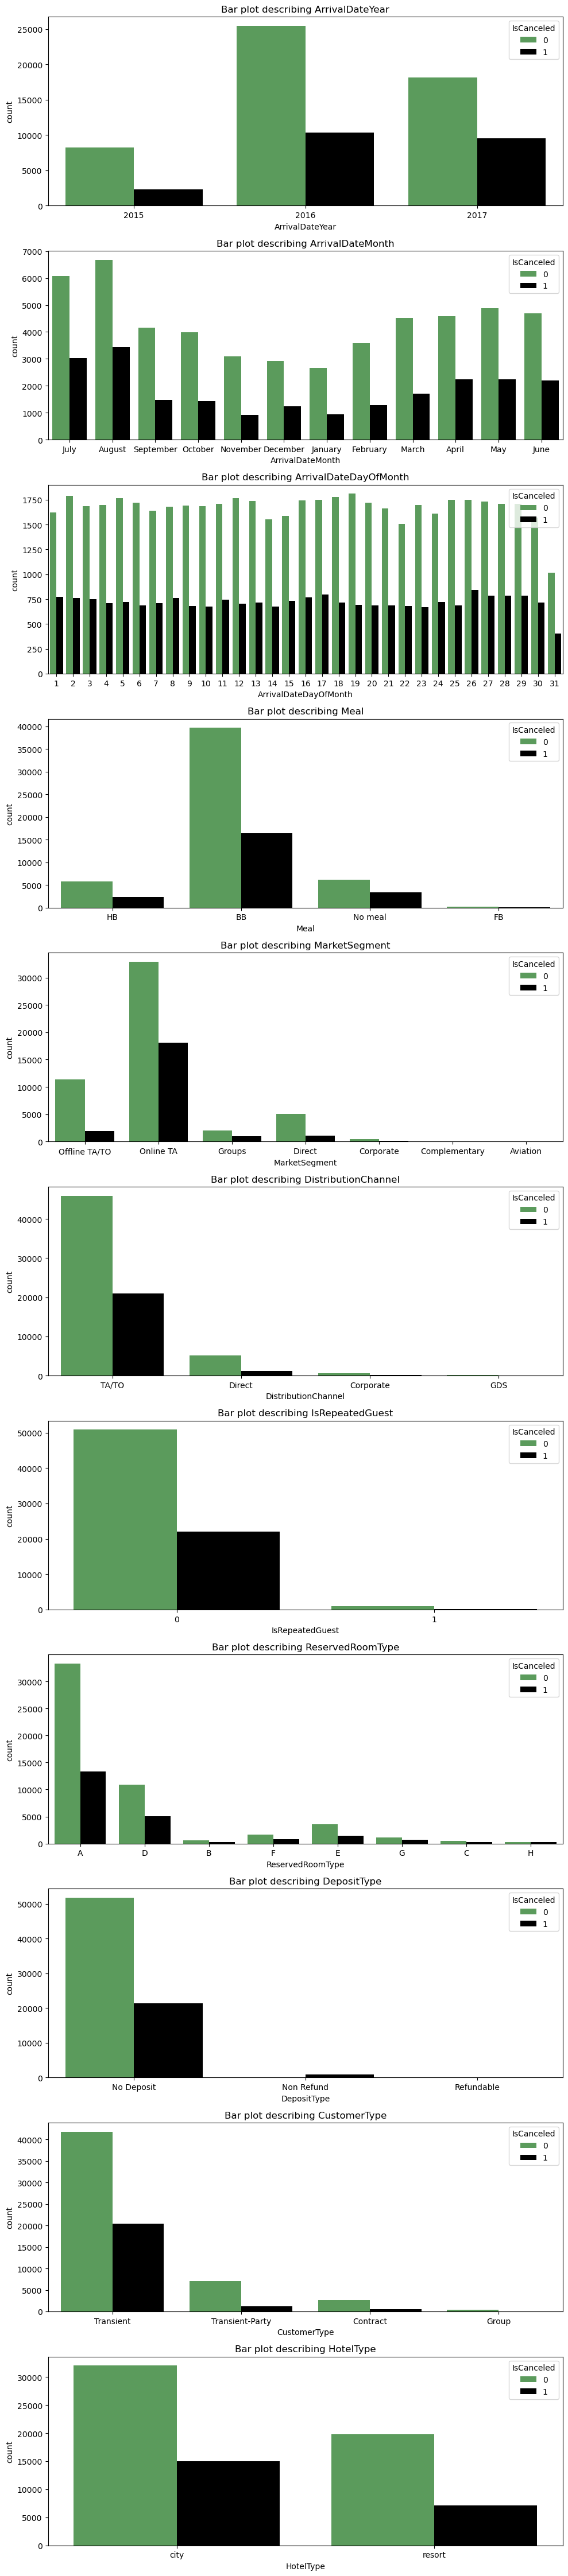

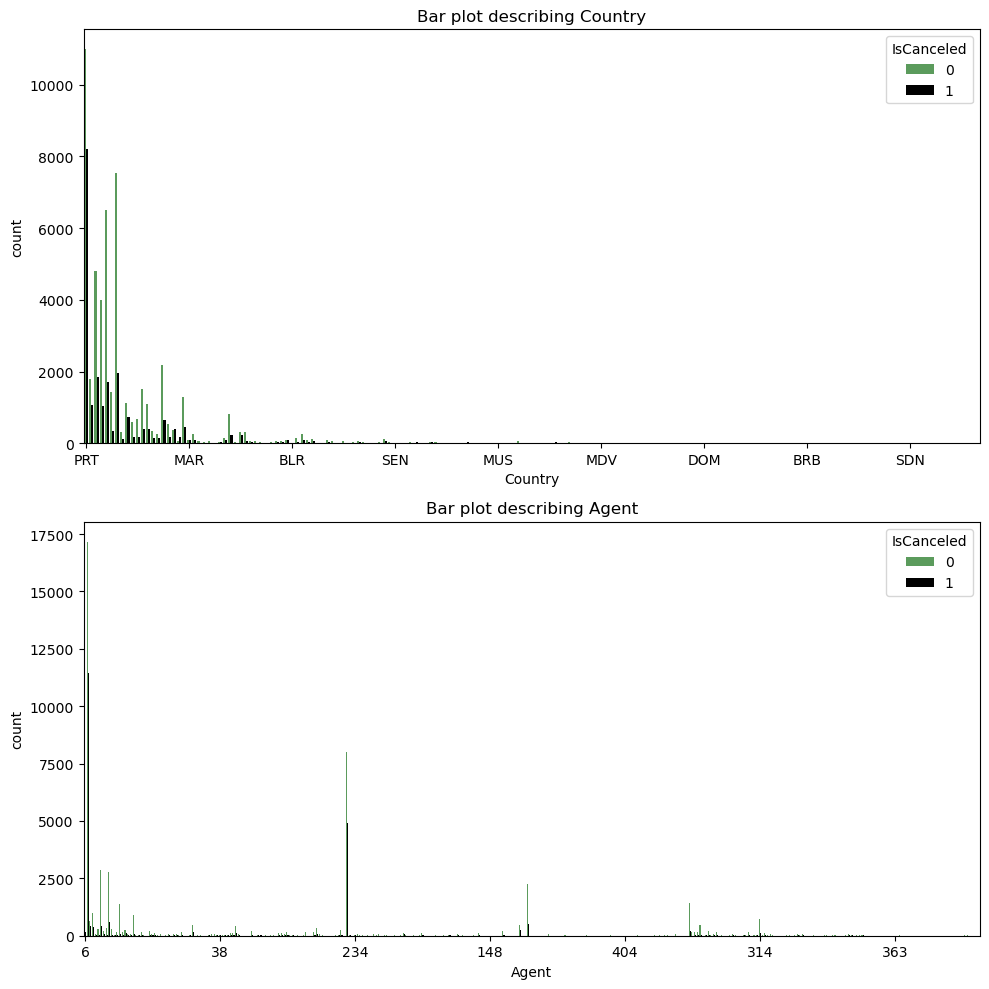

In [25]:
def plot_for_categorical_variables(df: pd.DataFrame, col_list: list, condense_x_ticks: bool, figsize: tuple):
    """Pass the dataframe and the column list to draw barplots for chosen columns. The list specifies which columns to include. If 
    condense_x_ticks is set to true, fewer x_ticks will be shown. This improves the readability. Figsize is adjustable as well.
    """
    

    fig, axes = plt.subplots(len(col_list), 1, figsize=figsize)
    axes = axes.flatten() 

    ## Plot the graph
    for i, col in enumerate(col_list):
        ax = axes[i]
        ax.set_title(f"Bar plot describing {col}") 
        sns.countplot(data=df, x=col, hue='IsCanceled', palette={1: 'black', 0:'#50a652'}, ax=ax) 
        if condense_x_ticks:
            ax.xaxis.set_major_locator(ticker.AutoLocator()) 
        
    plt.tight_layout()
    plt.show()

## Some categorical columns have numerous categories. Differentiate them and pass them into function separately.
categorical_col_normal = ['ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateDayOfMonth','Meal', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'ReservedRoomType', 'DepositType', 'CustomerType',
 'HotelType']
categorical_col_heavy = [ 'Country', 'Agent']

plot_for_categorical_variables(df, categorical_col_normal, condense_x_ticks=False, figsize=(10, 45))
plot_for_categorical_variables(df, categorical_col_heavy, condense_x_ticks=True, figsize=(10, 10))

In [26]:
## Investigate into the situation of non refund
print(f'No of people who chose non refund and showed up: {((df['DepositType'] =='Non Refund') & (df['IsCanceled']== 0)).sum()}')
print(f'No of people who chose non refund but cancelled: {((df['DepositType'] =='Non Refund') & (df['IsCanceled']== 1)).sum()}')

No of people who chose non refund and showed up: 19
No of people who chose non refund but cancelled: 803


In [27]:
## Show the share of each desposit type. 
print('The share of each desposit type:')
print(df['DepositType'].value_counts(normalize=True)) # Refundable is 0.0467% 

The share of each desposit type:
DepositType
No Deposit    0.988428
Non Refund    0.011099
Refundable    0.000473
Name: proportion, dtype: float64


In [28]:
## Show 10 agents who have the most share of the customer. 
print('10 agents who have the most share of the customer:')
print(df['Agent'].value_counts(normalize=True).sort_values(axis=0, ascending=False).head(10))

print('\n')

## Show 10 countries who have the greatest number of guests:
print('10 countries who have the greatest number of guests:')
print(df['Country'].value_counts(normalize=True).sort_values(axis=0, ascending=False).head(10))

10 agents who have the most share of the customer:
Agent
9      0.386484
240    0.174534
14     0.045018
7      0.044383
250    0.037254
241    0.022090
28     0.020132
8      0.018566
1      0.014610
6      0.013773
Name: proportion, dtype: float64


10 countries who have the greatest number of guests:
Country
PRT    0.259141
GBR    0.128126
FRA    0.110924
ESP    0.089671
DEU    0.068134
IRL    0.038388
ITA    0.038334
BEL    0.025776
BRA    0.025034
NLD    0.023886
Name: proportion, dtype: float64


> **Comments**:  
>
>Several observations can be made from the plots and the statistics:
>
>1. Time - Among the years, 2016 enjoyed more hotel guests. As for the months, as the data spans from July 1, 2015 and Aug 31, 2017, it is reasonable that we have more data points regarding August. According to the plot, the number of hotel guests fell from August to January and rose onwards. It was surprising that in December and Janauary, where there were Christmas and New Year holidays, did not have much guests compared with other months. 
>
>2. Preferences - Most guests prefered breakfast and bed only, as well as the no deposit option. Online travel agent was shown to be the most popular channel. 
>
>3. Market share - From the statistics, local guests were the majority, comprising nearly 37% of the guests. For foreign guests, Britain topped the list at around 11%. France ranked the third with a similar share as Britain (around 10%). Transient booking significantly outnumbered transient/party ones, implying that the majority of the guests were couples/single guests instead of a family or group.
>
>4. Cancellation behaviours: Group was more likely to cancell, and counterintuitively, non refund guests showed a high chance of cancellation. 

# 3. Data Transformtion for XGboost

In [29]:
## Countries and agents are relatively not predictive information, but there are too many categories of them. Only keep the top 10. The rest is classified as others
top_10_agent = ['9', '240', '1', '14', '7', '6', '250', '241', '28', '8']
df['Agent'] = np.where(df['Agent'].isin(top_10_agent), df['Agent'], 'others') 

top_10_country = ['PRT', 'GBR', 'FRA', 'ESP', 'DEU', 'ITA', 'IRL', 'BEL', 'BRA', 'USA'  ]
df['Country'] = np.where(df['Country'].isin(top_10_country), df['Country'], 'others') 



In [30]:
## sort time for ML
## As time series is involved, train-test split and cross validation must done in a way that avoids data leakage. 
## Only past data should be trained to predict future data.
df['ArrivalDateMonth'] = pd.to_datetime(df['ArrivalDateMonth'], format='%B').dt.month

df = df.sort_values(['ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateDayOfMonth'])
df

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,...,ReservedRoomType,BookingChanges,DepositType,Agent,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,HotelType
0,0,6,2015,7,1,0,2,1,0.0,0,...,A,0,No Deposit,6,0,Transient,0.00,0,0,city
1,1,88,2015,7,1,0,4,2,0.0,0,...,A,0,No Deposit,9,0,Transient,76.50,0,1,city
2,1,65,2015,7,1,0,4,1,0.0,0,...,A,0,No Deposit,9,0,Transient,68.00,0,1,city
3,1,92,2015,7,1,2,4,2,0.0,0,...,A,0,No Deposit,9,0,Transient,76.50,0,2,city
34906,1,257,2015,7,1,0,2,2,0.0,0,...,A,0,No Deposit,6,0,Transient,101.50,0,0,city
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119373,0,227,2017,8,31,2,5,2,1.0,0,...,A,0,No Deposit,241,0,Transient,125.58,0,1,resort
119379,0,217,2017,8,31,2,7,2,0.0,0,...,D,0,No Deposit,others,0,Contract,110.80,0,0,resort
119385,0,212,2017,8,31,2,8,2,1.0,0,...,A,1,No Deposit,others,0,Transient,89.75,0,0,resort
119388,0,211,2017,8,31,4,10,2,0.0,0,...,D,0,No Deposit,others,0,Contract,112.80,0,1,resort


In [31]:
## one-hot encoding (XGboost does not need to apply N-1 dummy variables)

df['is_city_hotel'] = np.where(df['HotelType'] == 'city', 1, 0) 
df.drop(columns=['HotelType'], inplace=True)

df_encoded = pd.get_dummies(df, columns=['ArrivalDateYear', 
                                         'ArrivalDateMonth', 
                                         'ArrivalDateDayOfMonth',
                                         'Meal',
                                         'Country', 
                                         'MarketSegment', 
                                         'DistributionChannel', 
                                         'ReservedRoomType', 
                                         'DepositType', 
                                         'Agent', 
                                         'CustomerType'])

In [32]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 74060 entries, 0 to 119389
Columns: 114 entries, IsCanceled to CustomerType_Transient-Party
dtypes: bool(98), float64(2), int64(14)
memory usage: 16.5 MB


In [33]:
df_encoded.head()

,IsCanceled,LeadTime,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,...,Agent_28,Agent_6,Agent_7,Agent_8,Agent_9,Agent_others,CustomerType_Contract,CustomerType_Group,CustomerType_Transient,CustomerType_Transient-Party
0,0,6,0,2,1,0.0,0,0,0,0,...,False,True,False,False,False,False,False,False,True,False
1,1,88,0,4,2,0.0,0,0,0,0,...,False,False,False,False,True,False,False,False,True,False
2,1,65,0,4,1,0.0,0,0,0,0,...,False,False,False,False,True,False,False,False,True,False
3,1,92,2,4,2,0.0,0,0,0,0,...,False,False,False,False,True,False,False,False,True,False
34906,1,257,0,2,2,0.0,0,0,1,0,...,False,True,False,False,False,False,False,False,True,False


# 4. Building XGboost

In [34]:
# Splitting into X and y
X = df_encoded.drop(columns=['IsCanceled'])
y = df_encoded['IsCanceled'].copy()

In [35]:
# Splitting into training and testing sets
X_train_temp, X_test, y_train_temp, y_test = train_test_split(X, y, random_state=42, shuffle=False) # time series data cannot shuffle

# Validation Set
X_train, X_val, y_train, y_val  = train_test_split(X_train_temp, y_train_temp, random_state=42, shuffle=False)

## Building preliminary model

In [36]:
tss = TimeSeriesSplit(n_splits=5)

In [37]:
# use randomizedsearchCV for prelim model, tradeoff accuracy for time
param_grid = {
    'max_depth': [2, 3, 5], 
    'learning_rate': [0.1, 0.125, 0.15], 
    'gamma': [0.5, 0.75, 1, 1.25],
    'reg_lambda': [2, 3, 5]}

optimal_params = RandomizedSearchCV(
    estimator=xgb.XGBClassifier(objective='binary:logistic',
                                seed=42,
                                early_stopping_rounds=10,
                                eval_metric='aucpr',
                                
                                subsample=0.9,
                                colsample_bytree=0.8,
                                tree_method='hist'),                          

    param_distributions=param_grid,
    n_iter=50,
    scoring='average_precision',  
    verbose=1,
    n_jobs=-1, 
    random_state=42,
    cv=tss
)


optimal_params.fit(X_train,
            y_train,
            verbose=1,
            eval_set=[(X_val, y_val)]) 

print(optimal_params.best_params_)                  


Fitting 5 folds for each of 50 candidates, totalling 250 fits
[0]	validation_0-aucpr:0.54160
[1]	validation_0-aucpr:0.61299
[2]	validation_0-aucpr:0.61596
[3]	validation_0-aucpr:0.61147
[4]	validation_0-aucpr:0.61803
[5]	validation_0-aucpr:0.61423
[6]	validation_0-aucpr:0.61855
[7]	validation_0-aucpr:0.62340
[8]	validation_0-aucpr:0.63979
[9]	validation_0-aucpr:0.64251
[10]	validation_0-aucpr:0.63922
[11]	validation_0-aucpr:0.64464
[12]	validation_0-aucpr:0.64492
[13]	validation_0-aucpr:0.64649
[14]	validation_0-aucpr:0.65061
[15]	validation_0-aucpr:0.65348
[16]	validation_0-aucpr:0.66243
[17]	validation_0-aucpr:0.66311
[18]	validation_0-aucpr:0.66175
[19]	validation_0-aucpr:0.66355
[20]	validation_0-aucpr:0.66299
[21]	validation_0-aucpr:0.66371
[22]	validation_0-aucpr:0.66628
[23]	validation_0-aucpr:0.67041
[24]	validation_0-aucpr:0.67154
[25]	validation_0-aucpr:0.67138
[26]	validation_0-aucpr:0.67076
[27]	validation_0-aucpr:0.67210
[28]	validation_0-aucpr:0.67244
[29]	validation_0-au

In [38]:
# hyperparameter on the boundary, retrain to get optimal hyperparameters
param_grid = {
    'max_depth': [5, 7, 9], 
    'learning_rate': [0.15, 0.2, 0.25], 
    'gamma': [1, 1.25, 1.5],
    'reg_lambda': [5, 7, 9, 11]}

optimal_params = RandomizedSearchCV(
    estimator=xgb.XGBClassifier(objective='binary:logistic',
                                seed=42,
                                early_stopping_rounds=10,
                                eval_metric='aucpr',
                                
                                subsample=0.9,
                                colsample_bytree=0.8,
                                tree_method='hist'),                          

    param_distributions=param_grid,
    n_iter=50,
    scoring='average_precision',  
    verbose=1,
    random_state=42,
    n_jobs=-1, 
    cv=tss
)


optimal_params.fit(X_train,
            y_train,
            verbose=1,
            eval_set=[(X_val, y_val)]) 

print(optimal_params.best_params_)                  


Fitting 5 folds for each of 50 candidates, totalling 250 fits
[0]	validation_0-aucpr:0.54788
[1]	validation_0-aucpr:0.62503
[2]	validation_0-aucpr:0.63023
[3]	validation_0-aucpr:0.64615
[4]	validation_0-aucpr:0.64858
[5]	validation_0-aucpr:0.64524
[6]	validation_0-aucpr:0.65684
[7]	validation_0-aucpr:0.66430
[8]	validation_0-aucpr:0.66995
[9]	validation_0-aucpr:0.66854
[10]	validation_0-aucpr:0.67062
[11]	validation_0-aucpr:0.67419
[12]	validation_0-aucpr:0.67611
[13]	validation_0-aucpr:0.67867
[14]	validation_0-aucpr:0.68152
[15]	validation_0-aucpr:0.68327
[16]	validation_0-aucpr:0.68253
[17]	validation_0-aucpr:0.68388
[18]	validation_0-aucpr:0.68589
[19]	validation_0-aucpr:0.68622
[20]	validation_0-aucpr:0.68756
[21]	validation_0-aucpr:0.68846
[22]	validation_0-aucpr:0.68954
[23]	validation_0-aucpr:0.69058
[24]	validation_0-aucpr:0.69150
[25]	validation_0-aucpr:0.69226
[26]	validation_0-aucpr:0.69335
[27]	validation_0-aucpr:0.69391
[28]	validation_0-aucpr:0.69476
[29]	validation_0-au

In [39]:
## the average precision score for train data
prelim_model = optimal_params.best_estimator_
print(f'The average precision score: {optimal_params.best_score_:.2f}')

The average precision score: 0.74


roc auc score on test data: 0.84
Average precision on test data: 0.72


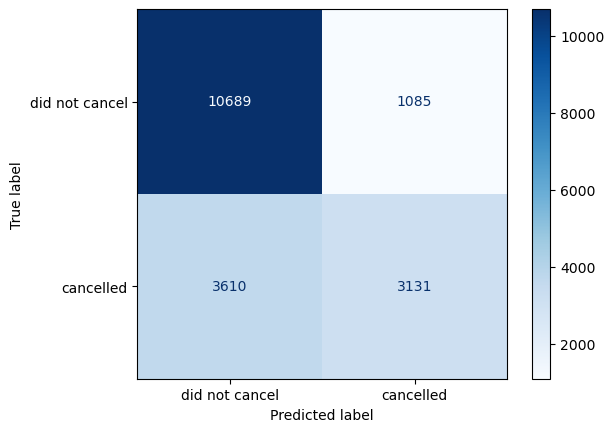

In [40]:
## AUC score and average precision score on test data
y_scores = prelim_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_scores)
print(f"roc auc score on test data: {roc_auc:.2f}")

avg_precision = average_precision_score(y_test, y_scores)
print(f"Average precision on test data: {avg_precision:.2f}")


## Drawing the confusion matrix on test data
ConfusionMatrixDisplay.from_estimator(
    prelim_model,
    X_test,
    y_test,
    display_labels=['did not cancel', 'cancelled'],
    cmap='Blues'
)
plt.show()

In [41]:
y_pred = prelim_model.predict(X_test)

## Accuracy on test data
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy on test data: {accuracy:.2f}') 

## F1_score on test data
F1_score = f1_score(y_test, y_pred)
print(f'F1 score on test data: {F1_score:.2f}') 



Accuracy on test data: 0.75
F1 score on test data: 0.57


## Permutation importance analysis

In [42]:
perm = PermutationImportance(prelim_model, random_state=42, n_iter=5).fit(X_test, y_test) 
eli5.show_weights(perm, feature_names=X_test.columns.values) 

Weight,Feature
0.0558 ± 0.0039,TotalOfSpecialRequests
0.0364 ± 0.0014,Agent_9
0.0357 ± 0.0028,Country_PRT
0.0184 ± 0.0016,LeadTime
0.0127 ± 0.0012,Agent_240
0.0124 ± 0.0017,RequiredCarParkingSpaces
0.0109 ± 0.0024,CustomerType_Transient
0.0079 ± 0.0023,MarketSegment_Online TA
0.0070 ± 0.0022,BookingChanges
0.0057 ± 0.0012,MarketSegment_Offline TA/TO


In [43]:
## Use domain knowledge and permutation importance scores to select features
## some top features in the permuation importance analysis overlap with the oberservations made before 
selected_columns =['TotalOfSpecialRequests', 'Agent_9', 'Country_PRT', 'LeadTime', 'Agent_240',
                    'RequiredCarParkingSpaces', 'CustomerType_Transient','MarketSegment_Online TA',
                    'BookingChanges', 'MarketSegment_Offline TA/TO', 'Agent_others', 'ADR',
                   'PreviousCancellations', 'PreviousBookingsNotCanceled','DepositType_Non Refund',
                   'IsCanceled'] # rmb to include outcome


In [44]:
df_selected = df_encoded[selected_columns]
df_selected

,TotalOfSpecialRequests,Agent_9,Country_PRT,LeadTime,Agent_240,RequiredCarParkingSpaces,CustomerType_Transient,MarketSegment_Online TA,BookingChanges,MarketSegment_Offline TA/TO,Agent_others,ADR,PreviousCancellations,PreviousBookingsNotCanceled,DepositType_Non Refund,IsCanceled
0,0,False,True,6,False,0,True,False,0,True,False,0.00,0,0,False,0
1,1,True,True,88,False,0,True,True,0,False,False,76.50,0,0,False,1
2,1,True,True,65,False,0,True,True,0,False,False,68.00,0,0,False,1
3,2,True,True,92,False,0,True,True,0,False,False,76.50,0,0,False,1
34906,0,False,True,257,False,0,True,False,0,True,False,101.50,1,0,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119373,1,False,False,227,False,0,True,True,0,False,False,125.58,0,0,False,0
119379,0,False,False,217,False,0,False,False,0,True,True,110.80,0,0,False,0
119385,0,False,False,212,False,0,True,False,1,True,True,89.75,0,0,False,0
119388,1,False,False,211,False,0,False,False,0,True,True,112.80,0,0,False,0


In [45]:
# Splitting into X and y
X = df_selected.drop(columns=['IsCanceled'])
y = df_selected['IsCanceled'].copy()

In [46]:
# Splitting into training and testing sets
X_train_temp, X_test, y_train_temp, y_test = train_test_split(X, y, random_state=42, shuffle=False) # time series data cannot shuffle

# Validation Set
X_train, X_val, y_train, y_val  = train_test_split(X_train_temp, y_train_temp, random_state=42, shuffle=False)

In [47]:
# use gridsearchcv to train exhaustively
param_grid = {
    'max_depth': [2, 3, 5], 
    'learning_rate': [0.1, 0.125, 0.15], 
    'gamma': [0.5, 0.75, 1, 1.25],
    'reg_lambda': [2, 3, 5]}

optimal_params = GridSearchCV(
    estimator=xgb.XGBClassifier(objective='binary:logistic',
                                seed=42,
                                early_stopping_rounds=10,
                                eval_metric='aucpr',
                                
                                subsample=0.9,
                                colsample_bytree=0.8,
                                tree_method='hist'),                         
                            
    param_grid=param_grid,
    scoring='average_precision',  
    verbose=1,
    n_jobs=-1, 
    cv=tss
)


optimal_params.fit(X_train,
            y_train,
            verbose=1,
            eval_set=[(X_val, y_val)]) 

print(optimal_params.best_params_)                  


Fitting 5 folds for each of 108 candidates, totalling 540 fits
[0]	validation_0-aucpr:0.62183
[1]	validation_0-aucpr:0.62351
[2]	validation_0-aucpr:0.61813
[3]	validation_0-aucpr:0.63262
[4]	validation_0-aucpr:0.63927
[5]	validation_0-aucpr:0.64160
[6]	validation_0-aucpr:0.65080
[7]	validation_0-aucpr:0.65111
[8]	validation_0-aucpr:0.65153
[9]	validation_0-aucpr:0.65252
[10]	validation_0-aucpr:0.65594
[11]	validation_0-aucpr:0.65457
[12]	validation_0-aucpr:0.65571
[13]	validation_0-aucpr:0.65542
[14]	validation_0-aucpr:0.65613
[15]	validation_0-aucpr:0.65630
[16]	validation_0-aucpr:0.65596
[17]	validation_0-aucpr:0.65834
[18]	validation_0-aucpr:0.66124
[19]	validation_0-aucpr:0.65973
[20]	validation_0-aucpr:0.65876
[21]	validation_0-aucpr:0.65923
[22]	validation_0-aucpr:0.66106
[23]	validation_0-aucpr:0.66187
[24]	validation_0-aucpr:0.66382
[25]	validation_0-aucpr:0.66547
[26]	validation_0-aucpr:0.66592
[27]	validation_0-aucpr:0.66647
[28]	validation_0-aucpr:0.66887
[29]	validation_0-a

In [48]:
# retrain
param_grid = {
    'max_depth': [5, 7, 9],
    'learning_rate': [0.15, 0.2], 
    'gamma': [0.2, 0.3, 0.4, 0.5],
    'reg_lambda': [3]}

optimal_params = GridSearchCV(
    estimator=xgb.XGBClassifier(objective='binary:logistic',
                                seed=42,
                                early_stopping_rounds=10,
                                eval_metric='aucpr',
                                
                                subsample=0.9,
                                colsample_bytree=0.8,
                                tree_method='hist'),                          
                            
    param_grid=param_grid,
    scoring='average_precision',  
    verbose=1,
    n_jobs=-1, 
    cv=tss
)


optimal_params.fit(X_train,
            y_train,
            verbose=1,
            eval_set=[(X_val, y_val)]) 

print(optimal_params.best_params_)                  


Fitting 5 folds for each of 24 candidates, totalling 120 fits
[0]	validation_0-aucpr:0.63664
[1]	validation_0-aucpr:0.64829
[2]	validation_0-aucpr:0.65150
[3]	validation_0-aucpr:0.64960
[4]	validation_0-aucpr:0.65775
[5]	validation_0-aucpr:0.66395
[6]	validation_0-aucpr:0.66671
[7]	validation_0-aucpr:0.66526
[8]	validation_0-aucpr:0.66588
[9]	validation_0-aucpr:0.66711
[10]	validation_0-aucpr:0.66884
[11]	validation_0-aucpr:0.66802
[12]	validation_0-aucpr:0.66945
[13]	validation_0-aucpr:0.67021
[14]	validation_0-aucpr:0.67072
[15]	validation_0-aucpr:0.67154
[16]	validation_0-aucpr:0.67211
[17]	validation_0-aucpr:0.67191
[18]	validation_0-aucpr:0.67154
[19]	validation_0-aucpr:0.67163
[20]	validation_0-aucpr:0.67234
[21]	validation_0-aucpr:0.67238
[22]	validation_0-aucpr:0.67264
[23]	validation_0-aucpr:0.67289
[24]	validation_0-aucpr:0.67394
[25]	validation_0-aucpr:0.67400
[26]	validation_0-aucpr:0.67426
[27]	validation_0-aucpr:0.67490
[28]	validation_0-aucpr:0.67510
[29]	validation_0-au

In [49]:
## the average precision score for train data
model = optimal_params.best_estimator_
print(f'The average precision score: {optimal_params.best_score_:.2f}')

The average precision score: 0.72


roc auc score on test data: 0.83
Average precision on test data: 0.69


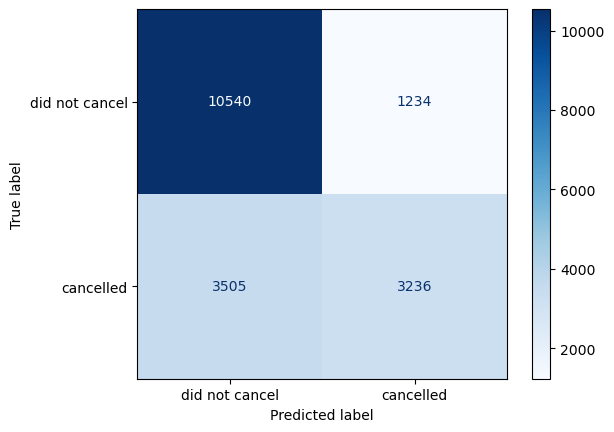

In [50]:
## AUC score and average precision score on test data
y_scores = model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_scores)
print(f"roc auc score on test data: {roc_auc:.2f}")

avg_precision = average_precision_score(y_test, y_scores)
print(f"Average precision on test data: {avg_precision:.2f}")


## Drawing the confusion matrix on test data
ConfusionMatrixDisplay.from_estimator(
    model,
    X_test,
    y_test,
    display_labels=['did not cancel', 'cancelled'],
    cmap='Blues'
)
plt.show()

In [51]:
y_pred = model.predict(X_test)

## Accuracy on test data
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy on test data: {accuracy:.2f}') 

## F1_score on test data
F1_score = f1_score(y_test, y_pred)
print(f'F1 score on test data: {F1_score:.2f}') 



Accuracy on test data: 0.74
F1 score on test data: 0.58


>**Comments**:   
> Although the final model scored a little worse than the prelim model regarding auc score, aucpr and accuracy, the model has a large explanability as it contains far fewer features.

## ROC, PR curve and threshold determination

ROC does not reflect the performance of model under imbalanced data. PR can compensate for this shortage. It is recommended to refer to both curves.

In [52]:
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

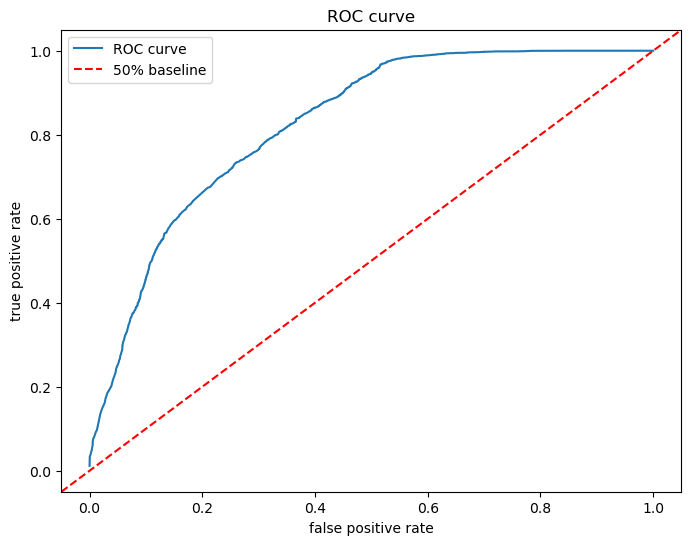

In [65]:
## Plot the roc curve
plt.figure(figsize=(8, 6))
sns.lineplot(x=fpr, y=tpr, label='ROC curve')
plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('ROC curve')
plt.axline((0, 0), slope=1, color='red', linestyle='--', label='50% baseline')

plt.legend()
plt.show()

In [54]:
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)

In [55]:
## One approach to determine an optimal threshold is by maximizing F1-score
## Find the threshold that gives the best F1-score
f1_scores = 2 * (precision * recall) / (precision + recall)

best_threshold_index = np.argmax(f1_scores)
best_f1 = f1_scores[best_threshold_index]
best_threshold = thresholds[best_threshold_index]

print(f"Best Threshold: {best_threshold:.2f}")
print(f"Best F1-score: {best_f1:.2f}")

Best Threshold: 0.20
Best F1-score: 0.68


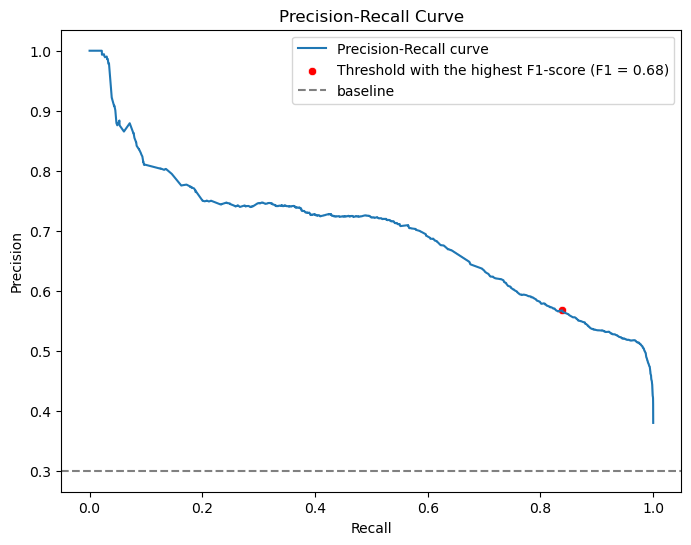

In [56]:
## Plot the PR curve
pr_baseline = 22209/(22209+51851)

plt.figure(figsize=(8, 6))
sns.lineplot(x=recall, y=precision, label='Precision-Recall curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')

sns.scatterplot(x=[recall[best_threshold_index]], y=[precision[best_threshold_index]],
                 color='red', label=f'Threshold with the highest F1-score (F1 = {best_f1:.2f})')
plt.axhline(y=pr_baseline, color='grey', linestyle='--', label='baseline')

plt.legend()
plt.show()

              precision    recall  f1-score   support

           0       0.87      0.63      0.73     11774
           1       0.57      0.84      0.68      6741

    accuracy                           0.71     18515
   macro avg       0.72      0.74      0.71     18515
weighted avg       0.76      0.71      0.71     18515



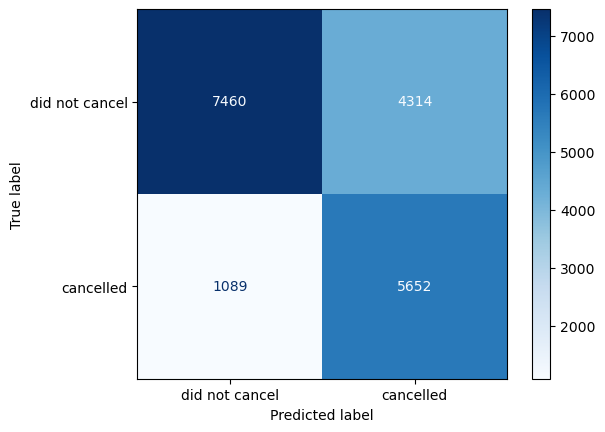

In [57]:
## Performance metrics of the new threshold
y_pred_best = (y_scores >= best_threshold).astype(int)

print(classification_report(y_test, y_pred_best))

## Confusion matrix of the new threshold
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=['did not cancel', 'cancelled'],
    cmap='Blues'
)
plt.show()

>**Comments**:
> With the new threshold, the following statistics are obtained:
>- Precision: 0.57,
>- Recall: 0.84,
>- F1-score: 0.68
>- Accuracy: 0.71
>- However, in practice hotel cancellation problem demands a lower false positive rate, or higher precision. The threshold obtained has sacrificed a great portion of precision. Lower precision should be avoided as it can lead to excessive overbooking, a practice that brings complaints and bad reputation for the hotel brand.  To tackle the issue, one way is to determine the threshold with a higher precision manually from the pr curve. In this dataset, thresholds within 0.7-0.8 precision and 0.4-0.6 recall region appears to be appropriate.

              precision    recall  f1-score   support

           0       0.77      0.88      0.82     11774
           1       0.72      0.54      0.61      6741

    accuracy                           0.75     18515
   macro avg       0.74      0.71      0.72     18515
weighted avg       0.75      0.75      0.74     18515



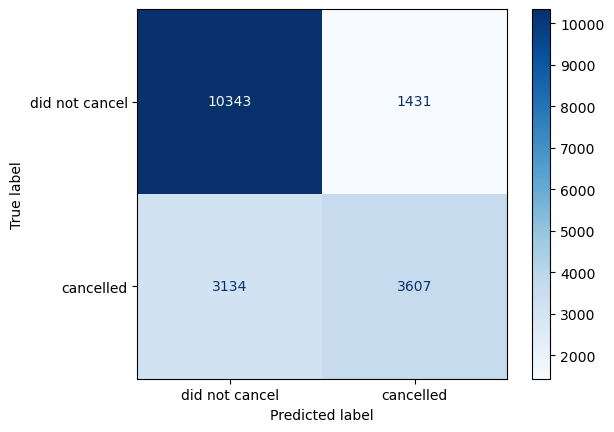

In [58]:
## Performance metrics of the new threshold
custom_threshold = 0.4
y_pred_custom = (y_scores >= custom_threshold).astype(int)

print(classification_report(y_test, y_pred_custom))

## Confusion matrix of the new threshold
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_custom,
    display_labels=['did not cancel', 'cancelled'],
    cmap='Blues',
    values_format='.0f'
)
plt.show()

# 5. Shap value interpretation

In [59]:
## Convert 0.4 to logit
cutoff = np.log(0.4 / (1-0.4))
print('Cutoff:', round(cutoff, 2)) 

Cutoff: -0.41


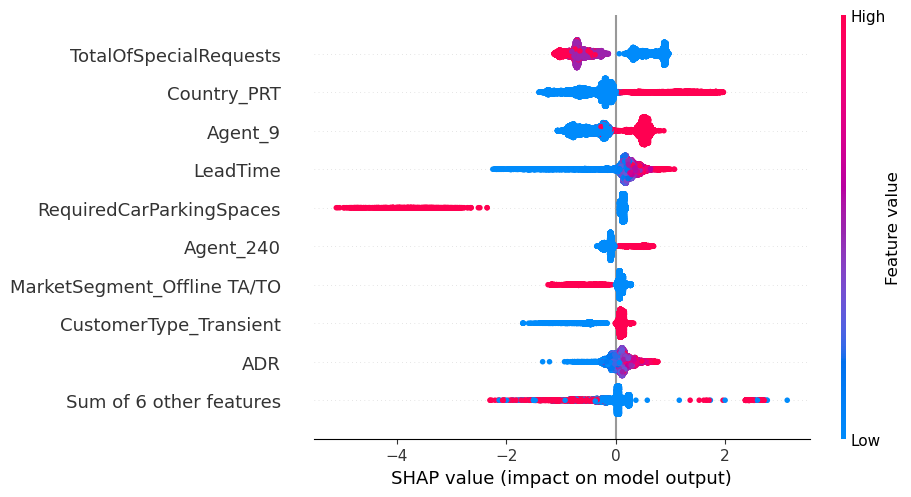

In [60]:
## Shap value analysis
explainer = shap.Explainer(model)
shap_values = explainer(X_test)

## SHAP Summary Plot
shap.plots.beeswarm(shap_values)


In [61]:
## Choose one correctly classified data as an example
true_indices = np.where(y_test)[0]
first_true_index = true_indices[0] 
if model.predict(X_test)[first_true_index] == y_test.iloc[first_true_index]:
    print('The sample is correctly predicted.')
else:
    print('It fails to predict correctly.')

It fails to predict correctly.


In [62]:
true_indices = np.where(y_test)[0]
second_true_index = true_indices[1] 
if model.predict(X_test)[second_true_index] == y_test.iloc[second_true_index]:
    print('The sample is correctly predicted.')
else:
    print('It fails to predict correctly.')

The sample is correctly predicted.


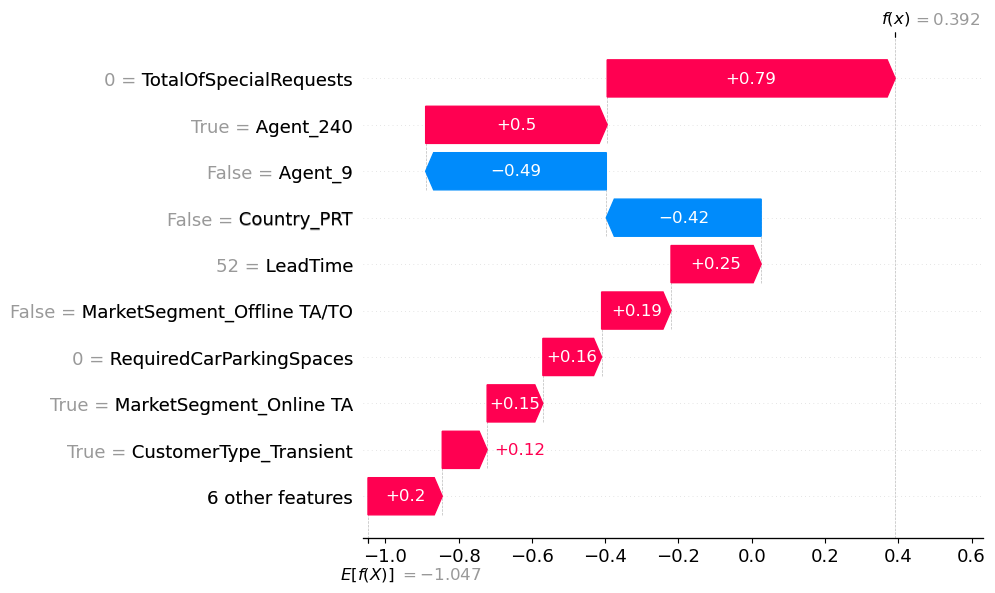

In [63]:
## visualize the prediction's explanation (classify as 'cancel' if greater than -0.41) 
shap.plots.waterfall(shap_values[second_true_index])

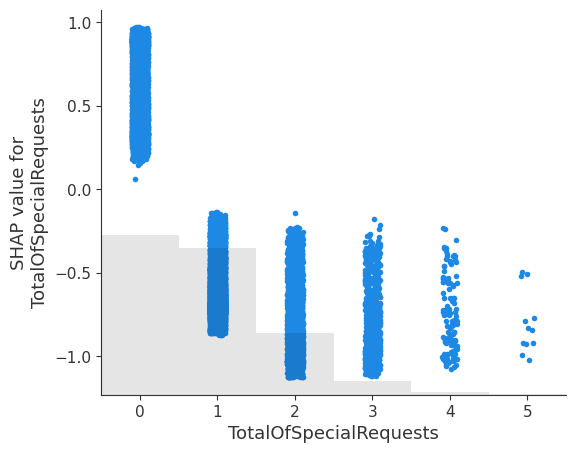

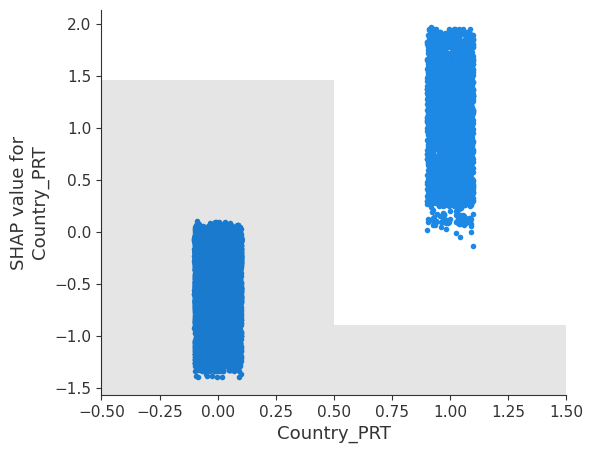

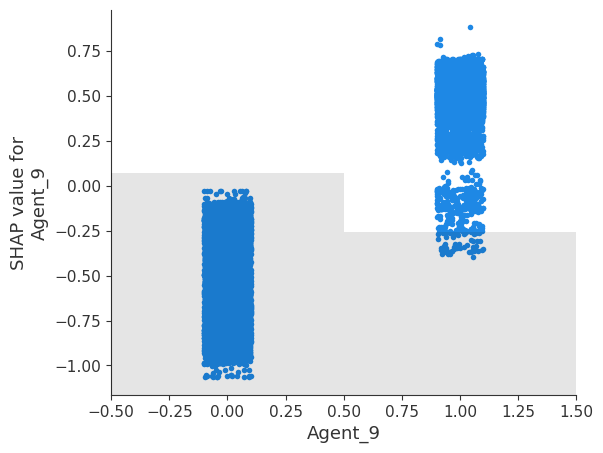

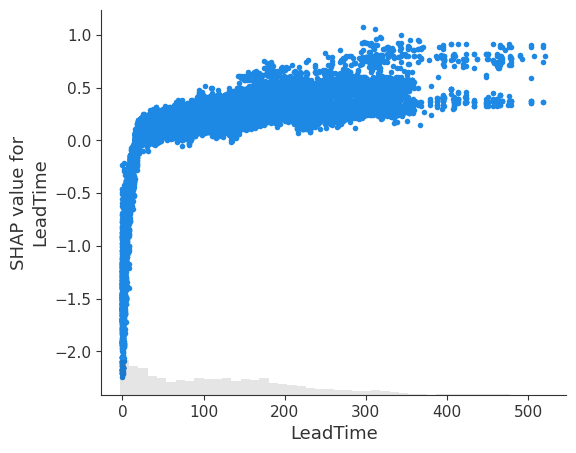

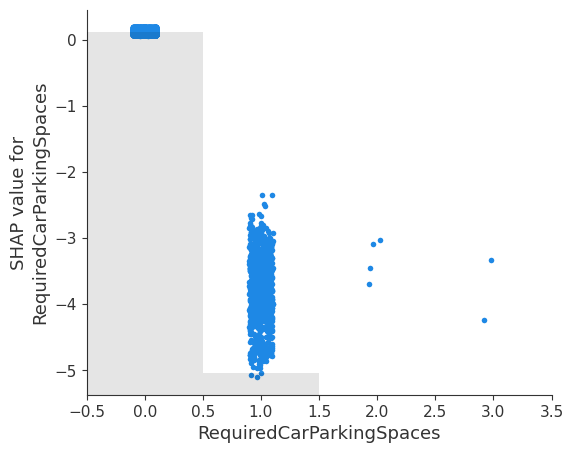

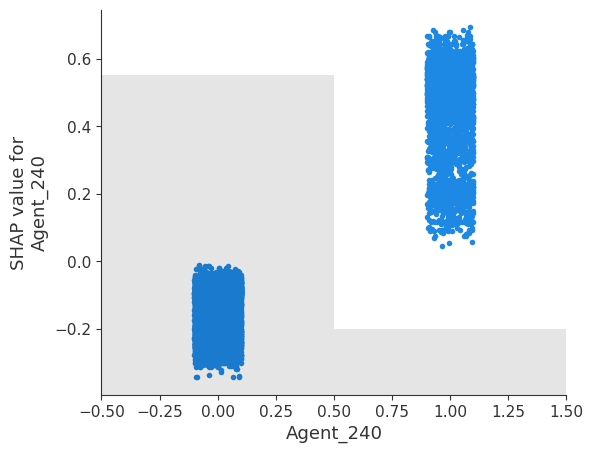

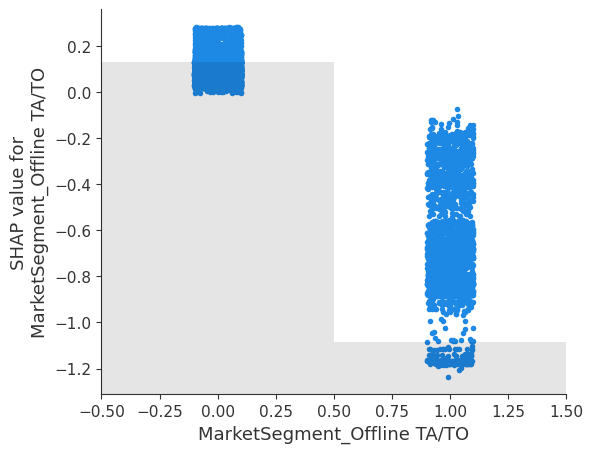

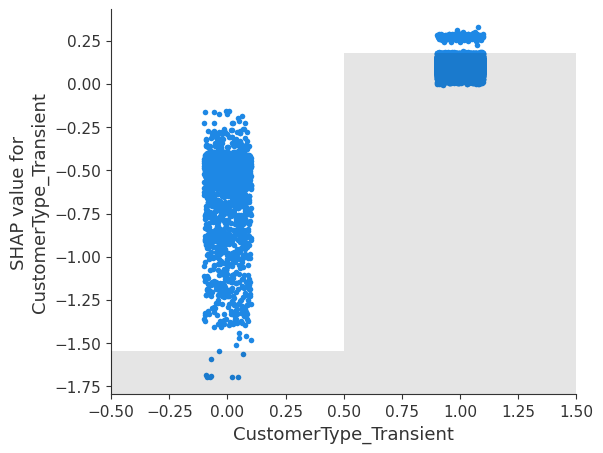

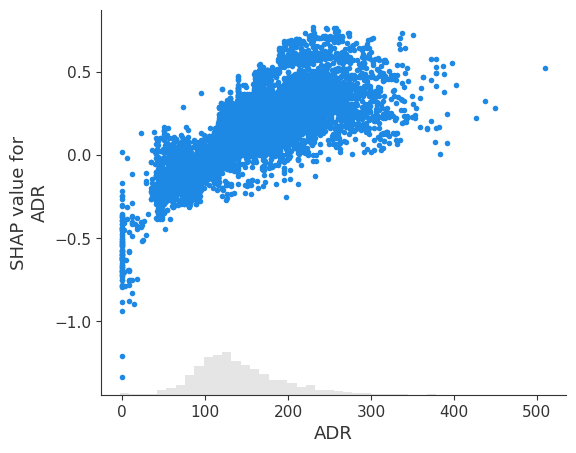

In [64]:
feature_list = ['TotalOfSpecialRequests', 'Country_PRT', 'Agent_9', 'LeadTime', 'RequiredCarParkingSpaces',
                'Agent_240', 'MarketSegment_Offline TA/TO', 'CustomerType_Transient', 'ADR']
for feature in feature_list:
    shap.plots.scatter(shap_values[:, feature])

>**Comments**:  
> Total number of special requests is the most predictive feature. If the guests made no requests, they were likely to cancel. The second most predictive feature is whether the guest was a Portugal. Being a local had a higher cancellation rate. This can be inferred that local trips are more spontaneous than overseas travels, they can be decided or cancelled easily. Out of expectations, customers from agent 9 are more likely to cancel. Similar trend can be observed in agent 240. One possible explanation is that agent 9 and 240 had poorer services and business practices. Longer lead time often indicates more certainties and tends to have higher cancellation rate. As for the car parking spaces request, a request made significantly reduces the likelihood of cancellations. Finally, people who booked through offline tour agents/ tour office had a lower probability to cancel. This group of people probably booked and cancelled hotels through offline channels, and offline booking and cancellations are more laborious and troublesome. This adds friction to any changes.      